## Import Libraries and Define Functions

In [1]:
import os
import sys
import math
import time
import glob
import scipy
import shutil
import warnings
import statistics

import numpy as np
import pandas as pd

import pyvista as pv
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import matplotlib.tri as tri
import matplotlib.colors as colors
import matplotlib.cm as cm

from scipy import stats, spatial
from scipy.stats import linregress
from scipy.interpolate import griddata
from scipy.interpolate import splprep, splev
from scipy.spatial import cKDTree
from numpy.polynomial import Polynomial as P
pd.options.mode.chained_assignment = None

import warnings
warnings.filterwarnings('ignore')

import econflux as ec
from resipy import Project

def local_grid_to_utm_along_line(local_grid_df, utm_pair1, utm_pair2):
    """
    Convert local grid coordinates to UTM coordinates by interpolating along the line
    defined by UTM pair 1 and UTM pair 2.

    Parameters:
        local_grid_df (DataFrame): DataFrame with 'x' column (local grid distance along profile).
        utm_pair1 (tuple): UTM coordinates of the first reference point (easting1, northing1).
        utm_pair2 (tuple): UTM coordinates of the second reference point (easting2, northing2).

    Returns:
        DataFrame: Copy of local_grid_df with added 'easting' and 'northing' columns.
    """
    # Extract UTM coordinates
    easting1, northing1 = utm_pair1
    easting2, northing2 = utm_pair2

    # Calculate differences
    delta_easting = easting2 - easting1
    delta_northing = northing2 - northing1

    # Normalize relative to max local x
    max_local_x = local_grid_df['X'].max()
    local_grid_df = local_grid_df.copy()
    local_grid_df['relative_position'] = local_grid_df['X'] / max_local_x

    # Interpolate UTM coordinates
    local_grid_df['easting'] = easting1 + local_grid_df['relative_position'] * delta_easting
    local_grid_df['northing'] = northing1 + local_grid_df['relative_position'] * delta_northing

    return local_grid_df

def direct_local_grid_to_utm_along_line(local_grid_df, coord_list, polyDeg=3, numSamples=1000, lineLength=95, correctCoords=False, checkLine=False, saveElec=False, elecPath=None):
    
    if (max(coord_list['x']) - min(coord_list['x'])) > (max(coord_list['y']) - min(coord_list['y'])):
        func = P.fit(coord_list['x'], coord_list['y'], polyDeg)
        xx, yy = func.linspace(len(coord_list))
        sampX, sampY = func.linspace(numSamples)
        if checkLine:
            plt.plot(coord_list['x'], coord_list['y'], 'o', label='Original Points')
            plt.plot(xx, yy, lw=2, label='Interpolated Line')
            plt.gca().set_aspect('equal')
            plt.legend(loc='upper right', bbox_to_anchor=(1.05, 1))
            plt.show()
            plt.close()
    else:
        func = P.fit(coord_list['y'], coord_list['x'], polyDeg)
        yy, xx = func.linspace(len(coord_list))
        sampY, sampX = func.linspace(numSamples)
        if checkLine:
            plt.plot(coord_list['y'], coord_list['x'], 'o', label='Original Points')
            plt.plot(yy, xx, lw=2, label='Interpolated Line')
            plt.gca().set_aspect('equal')
            plt.legend(loc='upper right', bbox_to_anchor=(1, 1.6))
            plt.show()
            plt.close()
    
    if correctCoords:
        coord_list['x'], coord_list['y'] = xx, yy
    
    linePos = np.zeros(numSamples)
    linePos = np.sqrt((sampX**2)+(sampY**2))
    if linePos[0] > linePos[-1]:
        relLinePos = abs((linePos - max(linePos)) / (max(linePos)-min(linePos)))
    else:
        relLinePos = (linePos - min(linePos)) / (max(linePos)-min(linePos))
    relLinePos *= lineLength
    
    elecDf = pd.DataFrame(np.transpose([relLinePos, np.zeros(numSamples)]), columns=['x', 'z'])
    
    tree = cKDTree(elecDf[['x', 'z']])
    dist, idx = tree.query(local_grid_df[['X', 'Z']])

    for i in range(len(local_grid_df)):
        local_grid_df.loc[i, ['x', 'y']] = [sampX[idx[i]], sampY[idx[i]]]

    if saveElec:
        coord_list.to_csv(elecPath + 'corrElecCoords.csv', index=False)
        
    return local_grid_df

    
def doi_flag_from_elevation(result_df, z_col='Z', doi_col='emi_DOI_arith',
                            flag_col='emi_DOI Flag_arith'):
    """Flag mapped cells below the EMI depth of investigation in the shared
    elevation frame (cell elevation below the DOI elevation). Call BEFORE any
    display shift of z_col so the two are comparable."""
    z = result_df[z_col].values
    doi = result_df[doi_col].values
    result_df[flag_col] = np.where(np.isfinite(doi) & (z < doi), 1.0, 0.0)
    return result_df

def plot_contour(ax, x, z, values, vmin, vmax, plotTyp='quad', title=None, xmin=None, xmax=None, cbbool=True, xlabel='Length (m)',
                 cmap='plasma', cbTicks=None, cbLabel=None, ri=None, riThresh=None, zbounds=None, numZtick=5, subfig=None, subfig2=None,
                 contourOrSmooth='smooth', plotMeas=False, measPoints=None, aspect=None):

        if plotTyp == 'quad':
            grid_x = np.linspace(x.min(), x.max(), 200)
            grid_z = np.geomspace(z.min(), z.max(), 200)
            grid_X, grid_Z = np.meshgrid(grid_x, grid_z)
        
            grid_values = griddata((x, z), values, (grid_X, grid_Z), method='linear')
            
            if ri is not None:
                
                grid_mask = griddata((x, z), ri, (grid_X, grid_Z), method='linear')
        
                grid_mask = np.ma.masked_where(grid_mask >  riThresh, grid_mask)
                
                grid_values = np.ma.masked_where(grid_mask.mask, grid_values)
        
            if contourOrSmooth == 'contour':
                contour = ax.contourf(grid_X, grid_Z, grid_values, norm=colors.LogNorm(vmin=vmin, vmax=vmax), levels=np.geomspace(vmin, vmax, 40), cmap=cmap, extend='both')
            elif contourOrSmooth == 'smooth':
                contour = ax.pcolormesh(grid_X, grid_Z, grid_values, norm=colors.LogNorm(vmin=vmin, vmax=vmax), shading='gouraud', cmap=cmap)
        elif plotTyp == 'tri':
            triang = tri.Triangulation(x, z)
            analyzer = tri.TriAnalyzer(triang)
            flat_mask = analyzer.get_flat_tri_mask(min_circle_ratio=0.02)
            if ri is not None:
                ri_high = np.asarray(ri) > riThresh
                t = triang.triangles
                ri_mask = (ri_high[t[:, 0]] | ri_high[t[:, 1]] | ri_high[t[:, 2]])
                triang.set_mask(flat_mask | ri_mask)
            else:
                triang.set_mask(flat_mask)

            contour = ax.tricontourf(triang, values,
                                     levels=np.geomspace(vmin, vmax, 256),
                                     norm=colors.LogNorm(vmin=vmin, vmax=vmax),
                                     cmap=cmap, extend='both')        
        elif plotTyp == 'points':
            if ri is not None:
                ri_mask = ri > riThresh
                x = x[ri_mask]
                z = z[ri_mask]
                values = values[ri_mask]
            contour = ax.scatter(x, z, s=15, c=values, cmap=cmap, norm=colors.LogNorm(vmin=vmin, vmax=vmax), linewidths=0.5, edgecolors='k', marker='s') 

        # Add scatter points on top of contour
        if plotMeas:
            if measPoints is not None:
                ax.scatter(measPoints.iloc[:, 0], measPoints.iloc[:, 1], color='white', edgecolor='black', s=0.05, zorder=10, label='Measurement Locations')
            else:
                ax.scatter(x, -1*z, color='white', edgecolor='black', s=0.05, zorder=10, label='Measurement Locations')
            ax.legend()
    
        if cbbool:
            cbar = plt.colorbar(contour, ax=ax, location='bottom', aspect=25, fraction=0.15, pad=0.3)
            if cbLabel is not None:
                cbar.set_label(cbLabel, fontsize=20, fontweight='bold')
            else:
                cbar.set_label(values.name, fontsize=20, fontweight='bold')
                
            if cbTicks is not None:
                cbar.set_ticks(cbTicks)
                cbar.set_ticklabels([str(t) for t in cbTicks])  # Format as strings
                cbar.ax.tick_params(labelsize=18)
        ax.set_xlabel(xlabel, fontsize = 25, fontweight='bold')
        ax.set_ylabel('Depth (m)', fontsize = 25, fontweight='bold')
        if title is not None:
            ax.set_title(title, fontsize = 25, pad=30)
        if zbounds is not None:
            ax.set_ylim(zbounds[0], zbounds[1])
            ax.set_yticks(np.linspace(zbounds[0], zbounds[1], numZtick))
        else:
            ax.set_ylim(0, z.max())
            ax.set_yticks(np.linspace(0, z.max(), numZtick))
        ax.invert_yaxis()
        if subfig:
            ax.annotate(subfig, xy=(0.005, 1.1), xycoords="axes fraction", fontsize=20, color='black', bbox=dict(facecolor="white", alpha=0.8, edgecolor='black'))
        if subfig2:
            ax.annotate(subfig2, xy=(0.038, 1.09), xycoords="axes fraction", fontsize=20, color='black')
        if (xmin is not None) & (xmax is not None):
            ax.set_xlim(xmin, xmax)  
        ax.tick_params(axis='both', which='major', labelsize=20)
            # Make border (spines) thicker
        for spine in ax.spines.values():
            spine.set_linewidth(2.0)
        if aspect is not None:
            ax.set_aspect(aspect)

def along_line_coord(anchor_df, xcol='x', ycol='y', deg=3, nsamp=5000, flip=True):
    """Along-line distance using the same fitted-line projection as the 2-D sections.
    Returns a callable mapping a DataFrame's (x,y) to metres along the line."""
    ax_, ay_ = anchor_df[xcol].values, anchor_df[ycol].values
    if (ax_.max() - ax_.min()) >= (ay_.max() - ay_.min()):
        func = P.fit(ax_, ay_, deg); sampX, sampY = func.linspace(nsamp)
    else:
        func = P.fit(ay_, ax_, deg); sampY, sampX = func.linspace(nsamp)
    linePos = np.sqrt(sampX**2 + sampY**2)
    if linePos[0] > linePos[-1]:
        rel = np.abs((linePos - linePos.max()) / (linePos.max() - linePos.min()))
    else:
        rel = (linePos - linePos.min()) / (linePos.max() - linePos.min())
    rel *= np.sqrt((ax_.max()-ax_.min())**2 + (ay_.max()-ay_.min())**2)
    tree = cKDTree(np.column_stack([sampX, sampY]))
    relseq = rel[::-1] if flip else rel
    def coord(df):
        _, idx = tree.query(df[[xcol, ycol]].values)
        return relseq[idx]
    return coord

API path =  C:\Users\Chris\miniconda3\envs\geophysics\Lib\site-packages\resipy
ResIPy version =  3.6.6
cR2.exe found and up to date.
R3t.exe found and up to date.
cR3t.exe found and up to date.


In [2]:
### Define font properties

titleFontKws = {
    'fontsize': 16,
    'fontweight': 'bold',
    }

subtitleFontKws = {
    'fontsize': 12,
    'fontweight': 'bold',
    }

labelFontKws = {
    'fontsize': 14,
    'fontweight': 'bold',
    }

tickLabelFontKws = {
    'labelsize': 10,
    }

cbarTitleKws = {
    'fontsize': 14,
    'fontweight': 'bold'}

cbarTickKws = {
    'fontsize': 12,
    }

# Define font parameters
plt.rcParams['font.family'] = 'Cambria'
plt.rcParams['font.weight'] = 'bold'

fontkwDict = {'fontfamily': 'Cambria',
              'fontweight': 'bold',
              'titlefontsize': titleFontKws['fontsize'],
              'titlefontweight': titleFontKws['fontweight'],
              'axislabelsize': labelFontKws['fontsize'],
              'axislabelweight': labelFontKws['fontweight'],
              'axisticksize': tickLabelFontKws['labelsize'],
              'cbartitlesize': cbarTitleKws['fontsize'],
              'cbartitleweight': cbarTitleKws['fontweight'],
              'cbarticklabelsize': cbarTickKws['fontsize']}

In [3]:
datDir = r"C:\Users\Chris\Documents\GitHub\EConflux\examples\waterborne_em2er\\"
figdir = r'C:\Users\Chris\Documents\GitHub\EConflux\examples\waterborne_em2er\wERI Inversion - Informed (reg_mode = 1)\figures\\'  #  Directory where the figures will be saved to

eminame = r"C:\Users\Chris\Documents\GitHub\EConflux\examples\waterborne_em2er\EMI Inversion Files\SDEMI4edit_Paraview.csv"

## Invert ERI Data w/o EMI-Informed Forward Model

In [4]:
#----------------------------------------------------------------------------------------------------------------
# Define working directory (for inversion w/o EMI informing), list of surveys, and electrode positions
#----------------------------------------------------------------------------------------------------------------
# Define path to working directory
dRef = r"C:\Users\Chris\Documents\GitHub\EConflux\examples\waterborne_em2er\wERI Inversion - Raw (reg_mode = 0)"
data_folder =  r"C:\Users\Chris\Documents\GitHub\EConflux\examples\waterborne_em2er\Electrode mapping from Boat GPS\ERI Survey Files"
refPath = glob.glob(os.path.join(data_folder, "*.csv"))

electrode_folder =  r"C:\Users\Chris\Documents\GitHub\EConflux\examples\waterborne_em2er\Electrode mapping from Boat GPS\ERI Electrode Files"
electrode_list = glob.glob(os.path.join(electrode_folder, "*.csv"))

In [5]:
survey_list = []
results_list = []
rms_list = []
errList = []

for i in range(len(refPath)):
    print('---------------------------------------------------------------------------------------------------------')
    print('^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^')
    print('STARTING SURVEY', str(i))
    print('^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^')
    print('---------------------------------------------------------------------------------------------------------')
    
    print(f'The length of refPath is {len(refPath)}')
    k = Project(typ = 'R2', dirname = dRef)
    k.createSurvey(refPath[i], ftype = 'Syscal')
    k.importElec(electrode_list[i])
    elecUTM = k.elec.copy()
    if (max(k.elec['x']) - min(k.elec['x'])) > (max(k.elec['y']) - min(k.elec['y'])):
        k.elec2distance()
    else:
        k.elec2distance(yDominant=True)    
    k.createMesh()

    k.param['a_wgt'] = 0.001
    k.param['b_wgt'] = 0.02
    
    k.invert(pseudoStart=False)

    survErr = k.surveys[0].df['resInvError'].values
    survey_list.append(k.surveys[0].df)
    results_list.append(k.meshResults[0].df)
    rms_list.append(k.getRMS())
    for err in survErr:
        errList.append(err)

---------------------------------------------------------------------------------------------------------
^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
STARTING SURVEY 0
^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
---------------------------------------------------------------------------------------------------------
The length of refPath is 64
Working directory is: C:\Users\Chris\Documents\GitHub\EConflux\examples\waterborne_em2er\wERI Inversion - Raw (reg_mode = 0)
clearing dirname
Project created!
filterData: 0 / 10 quadrupoles removed.
0/10 reciprocal measurements found.
Creating triangular mesh...done (2612 elements)
Writing .in file and protocol.dat... done

--------------------- MAIN INVERSION ------------------


 >> R  2    R e s i s t i v i t y   I n v e r s i o n   v4.10 <<

 >> D a t e : 29 - 06 - 2026
 >> My beautiful survey                            

4 (0.625 %) measurements outside of +/- 3% error threshold.
Mean of inversion errors is -0.318013515625 %


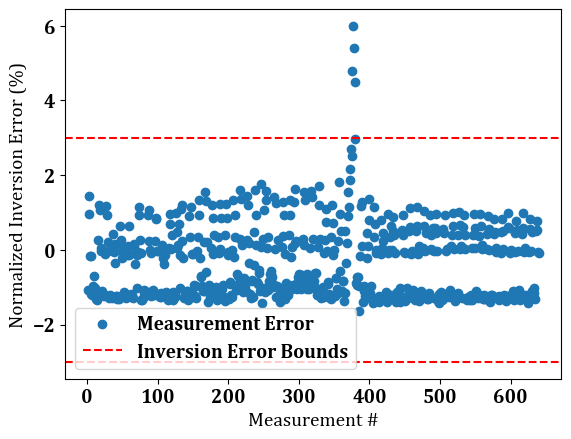

In [6]:
rms_df = pd.DataFrame({'rms_ap_rm1': rms_list})
rms_df.to_csv(dRef + '\\rms_nap_rm0.csv', index = None)
fig, ax = plt.subplots()
numMeas = np.linspace(1, len(errList), len(errList))
ax.scatter(numMeas, errList, label='Measurement Error')
ax.axhline(y=3, linestyle='--', color='r')
ax.axhline(y=-3, linestyle='--', color='r', label='Inversion Error Bounds')
ax.set_xlabel('Measurement #')
ax.set_ylabel('Normalized Inversion Error (%)')
ax.legend()

inverrs = np.array(errList)
baderridx = np.where((inverrs > 3) | (inverrs < -3))
baderrs = inverrs[baderridx]
print(f'{len(baderrs)} ({(len(baderrs)/len(inverrs))*100} %) measurements outside of +/- 3% error threshold.')
print(f'Mean of inversion errors is {np.mean(inverrs)} %')

In [7]:
averaged_list = []

for i, df in enumerate(results_list):  # now each element is a DataFrame
    df = df.copy()
    
    # Subset X ranges
    temp1 = df[(df['X'] > 8.0) & (df['X'] < 9.25)]
    
    for temp, eX_val in zip([temp1], [7]):
        if temp.empty:
            continue
        
        # Create Z bins using 0.1 width (so ±0.05 will fall into same bin)
        temp["Z_bin"] = (temp["Z"] / 0.1).round() * 0.1
        
        # Average numeric columns within Z_bin
        df_avg = temp.groupby("Z_bin", as_index=False).mean(numeric_only=True)
        
        # Add eX, eY, and source info
        df_avg["eX"] = eX_val
        df_avg["eY"] = 12
        df_avg["source"] = i
        
        averaged_list.append(df_avg)

# Combine all
final_averaged_df_raw = pd.concat(averaged_list, ignore_index=True)
final_averaged_df_raw.head(40)

,Z_bin,param,elm_id,region,cellType,X,Y,Z,Resistivity(ohm.m),Resistivity(log10),Sensitivity(log10),Scaled_Sensitivity(log10),Conductivity(mS/m),eX,eY,source
0,-5.3,438.000000,438.000000,1.0,5.0,8.647330,0.0,-5.302793,1.294560,0.112120,-2.814760,-1.431330,772.463231,7,12,0
1,-5.1,336.000000,336.000000,1.0,5.0,8.638440,0.0,-5.107112,1.282135,0.107925,-2.573115,-1.157840,779.974528,7,12,0
2,-4.7,395.000000,395.000000,1.0,5.0,8.619535,0.0,-4.723065,1.259725,0.100265,-2.609260,-1.153895,793.863186,7,12,0
3,-4.5,520.000000,520.000000,1.0,5.0,8.921215,0.0,-4.520400,1.237625,0.092560,-2.377330,-0.868500,808.091884,7,12,0
4,-4.2,266.000000,266.000000,1.0,5.0,8.597693,0.0,-4.174943,1.230470,0.090070,-2.458050,-0.882550,812.697587,7,12,0
5,-4.1,775.000000,775.000000,1.0,5.0,9.193910,0.0,-4.138573,1.196900,0.078060,-2.524400,-0.851840,835.491687,7,12,0
6,-4.0,282.500000,282.500000,1.0,5.0,8.593652,0.0,-4.000357,1.217010,0.085265,-2.249645,-0.624530,821.796089,7,12,0
7,-3.7,221.500000,221.500000,1.0,5.0,8.595138,0.0,-3.660147,1.201220,0.079580,-2.286595,-0.622825,832.655709,7,12,0
8,-3.5,392.000000,392.000000,1.0,5.0,8.603567,0.0,-3.490187,1.187707,0.074583,-2.088063,-0.353290,842.450903,7,12,0
9,-3.2,449.333333,449.333333,1.0,5.0,8.604148,0.0,-3.171416,1.179310,0.071470,-2.179150,-0.352780,848.572852,7,12,0


In [8]:
elecWB = r"C:\Users\Chris\Documents\GitHub\EConflux\examples\waterborne_em2er\Electrode mapping from Boat GPS\wERT_elec_combined.csv"
electrodes = pd.read_csv(elecWB)

In [9]:
# Assuming 'electrodes' DataFrame is already defined and has been filtered as per your previous request
# 'filtered' DataFrame is created by filtering 'electrodes'
# filtered = electrodes[electrodes['label'].astype(str).str.contains(r'( 5| 9)')].reset_index(drop=True)
filtered = electrodes[electrodes['label'].astype(str).str.contains(r'( 7)')].reset_index(drop=True)

# Create a mapping series to determine which row of 'filtered' to use
# The index will be 'source' and the values will be '0' for eX=6 and '1' for eX=12
# This assumes that for each source, eX=6 is always followed by eX=12
# The final index into 'filtered' is calculated as 2 * source + eX_index
final_averaged_df_raw['eX_index'] = final_averaged_df_raw['eX'].map({7: 0})
final_averaged_df_raw['filtered_row_index'] = final_averaged_df_raw['source'] + final_averaged_df_raw['eX_index']

# Create dictionaries for fast lookup
x_map = filtered['x'].to_dict()
y_map = filtered['y'].to_dict()

# Map the values to new columns
final_averaged_df_raw['x'] = final_averaged_df_raw['filtered_row_index'].map(x_map)
final_averaged_df_raw['y'] = final_averaged_df_raw['filtered_row_index'].map(y_map)

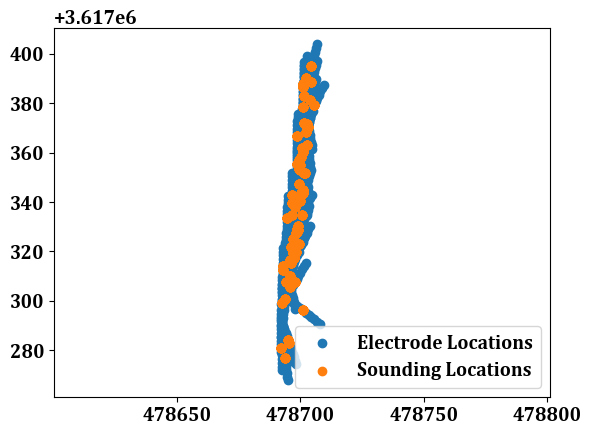

In [10]:
plt.scatter(electrodes['x'], electrodes['y'], label='Electrode Locations')
plt.scatter(final_averaged_df_raw['x'], final_averaged_df_raw['y'], label='Sounding Locations')
plt.axis('equal')
plt.legend()

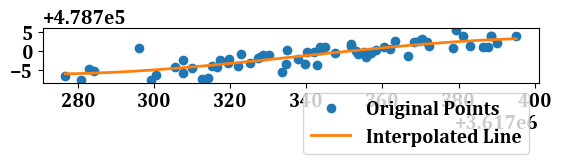

array([0.00000000e+00, 2.36481225e-02, 4.72964607e-02, ...,
       1.19152989e+02, 1.19176689e+02, 1.19200389e+02])

In [11]:
xs = final_averaged_df_raw.loc[0::31, 'x']
ys = final_averaged_df_raw.loc[0::31, 'y']
if (max(final_averaged_df_raw['x']) - min(final_averaged_df_raw['x'])) > (max(final_averaged_df_raw['y']) - min(final_averaged_df_raw['y'])):
    func = P.fit(xs, ys, 3)
    xx, yy = func.linspace(len(xs))
    sampX, sampY = func.linspace(5000)
    plt.plot(xs, ys, 'o', label='Original Points')
    plt.plot(xx, yy, lw=2, label='Interpolated Line')
    plt.gca().set_aspect('equal')
    plt.legend(loc='upper right', bbox_to_anchor=(0, 1))
    plt.show()
    plt.close()
else:
    func = P.fit(ys, xs, 3)
    yy, xx = func.linspace(len(ys))
    sampY, sampX = func.linspace(5000)
    plt.plot(ys, xs, 'o', label='Original Points')
    plt.plot(yy, xx, lw=2, label='Interpolated Line')
    plt.gca().set_aspect('equal')
    plt.legend(loc='upper right', bbox_to_anchor=(1, 0))
    plt.show()
    plt.close()

linePos = np.zeros(5000)
linePos = np.sqrt((sampX**2)+(sampY**2))
if linePos[0] > linePos[-1]:
    relLinePos = abs((linePos - max(linePos)) / (max(linePos)-min(linePos)))
else:
    relLinePos = (linePos - min(linePos)) / (max(linePos)-min(linePos))
relLinePos *= np.sqrt((final_averaged_df_raw['x'].max()-final_averaged_df_raw['x'].min())**2 + (final_averaged_df_raw['y'].max()-final_averaged_df_raw['y'].min())**2)
relLinePos

In [12]:
elecDf = pd.DataFrame(np.transpose([sampX, sampY, relLinePos, np.zeros(5000)]), columns=['x', 'y', 'X', 'Z'])

tree = cKDTree(elecDf[['x', 'y']])
dist, idx = tree.query(final_averaged_df_raw[['x', 'y']])

for i in range(len(final_averaged_df_raw)):
    final_averaged_df_raw.loc[i, 'X'] = relLinePos[::-1][idx[i]]

print(final_averaged_df_raw['X'].min())
print(final_averaged_df_raw['X'].max())
final_averaged_df_raw.to_csv(r"C:\Users\Chris\Documents\GitHub\EConflux\examples\waterborne_em2er\wERI Inversion - Raw (reg_mode = 0)\ERT_not_informed.csv", index=None)
final_averaged_df_raw

0.0
119.20038855550371


,Z_bin,param,elm_id,region,cellType,X,Y,Z,Resistivity(ohm.m),Resistivity(log10),Sensitivity(log10),Scaled_Sensitivity(log10),Conductivity(mS/m),eX,eY,source,eX_index,filtered_row_index,x,y
0,-5.3,438.000000,438.000000,1.0,5.0,0.000000,0.0,-5.302793,1.294560,0.112120,-2.814760,-1.431330,772.463231,7,12,0,0,0,478704.101165,3.617395e+06
1,-5.1,336.000000,336.000000,1.0,5.0,0.000000,0.0,-5.107112,1.282135,0.107925,-2.573115,-1.157840,779.974528,7,12,0,0,0,478704.101165,3.617395e+06
2,-4.7,395.000000,395.000000,1.0,5.0,0.000000,0.0,-4.723065,1.259725,0.100265,-2.609260,-1.153895,793.863186,7,12,0,0,0,478704.101165,3.617395e+06
3,-4.5,520.000000,520.000000,1.0,5.0,0.000000,0.0,-4.520400,1.237625,0.092560,-2.377330,-0.868500,808.091884,7,12,0,0,0,478704.101165,3.617395e+06
4,-4.2,266.000000,266.000000,1.0,5.0,0.000000,0.0,-4.174943,1.230470,0.090070,-2.458050,-0.882550,812.697587,7,12,0,0,0,478704.101165,3.617395e+06
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2010,-0.6,263.000000,263.000000,1.0,5.0,119.200389,0.0,-0.604468,0.680130,-0.168375,-0.771145,1.406815,1476.847193,7,12,63,0,63,478693.603452,3.617277e+06
2011,-0.5,594.000000,594.000000,1.0,5.0,119.200389,0.0,-0.515232,0.676140,-0.170150,-1.068867,1.390957,1480.249403,7,12,63,0,63,478693.603452,3.617277e+06
2012,-0.4,756.500000,756.500000,1.0,5.0,119.200389,0.0,-0.431223,0.642085,-0.192495,-0.593660,1.830455,1558.078223,7,12,63,0,63,478693.603452,3.617277e+06
2013,-0.2,608.333333,608.333333,1.0,5.0,119.200389,0.0,-0.218188,0.649500,-0.187993,-0.729143,1.682130,1543.689599,7,12,63,0,63,478693.603452,3.617277e+06


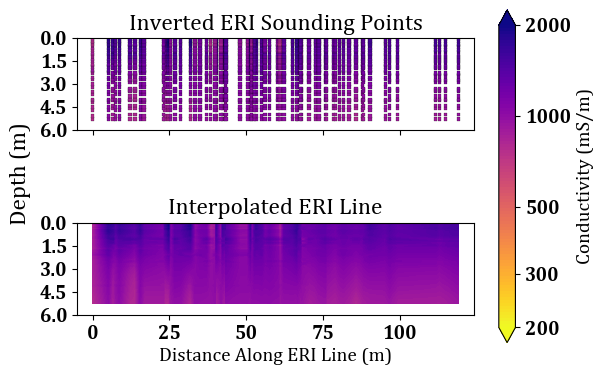

In [13]:
triang = tri.Triangulation(final_averaged_df_raw['X'],-final_averaged_df_raw['Z_bin'])
analyzer = tri.TriAnalyzer(triang)
triang.set_mask(analyzer.get_flat_tri_mask(min_circle_ratio=0.02))
tickLabels = [200, 300, 500, 1000, 2000]
fig, axs = plt.subplots(nrows=2, sharex=True, sharey=True)

axs[0].scatter(final_averaged_df_raw['X'], -final_averaged_df_raw['Z_bin'], s=6, c=final_averaged_df_raw['Conductivity(mS/m)'], cmap='plasma_r', norm=colors.LogNorm(vmin=tickLabels[0], vmax=tickLabels[-1]), linewidths=0.15, edgecolors='k', marker='s') 
axs[0].set_title('Inverted ERI Sounding Points')
axs[0].set_aspect(5)

c = axs[1].tricontourf(triang, np.log10(final_averaged_df_raw['Conductivity(mS/m)']), levels=np.linspace(np.log10(tickLabels[0]), np.log10(tickLabels[-1]), 100), extend='both', cmap='plasma_r')
axs[1].set_title('Interpolated ERI Line')
axs[1].set_aspect(5)
axs[1].set_xlabel('Distance Along ERI Line (m)')
axs[1].set_yticks([0.0, 1.5, 3.0, 4.5, 6.0])
axs[1].invert_yaxis()
axs[1].set_xlim(-5, final_averaged_df_raw['X'].max()+5)
fig.supylabel('Depth (m)')

fig.subplots_adjust(hspace=0) 

cb = fig.colorbar(
    c,
    ticks=[np.log10(t) for t in tickLabels],
    orientation='vertical', location='right',
    pad=0.05, shrink=0.9, extend='both', ax=axs)
cb.ax.set_yticklabels([str(t) for t in tickLabels])
cb.set_label('Conductivity (mS/m)')

## Running Inversion w/ EMI-Informed Forward Model

In [14]:
#----------------------------------------------------------------------------------------------------------------
# Define working directory (for inversion w/o EMI informing), list of surveys, and electrode positions
#----------------------------------------------------------------------------------------------------------------
# Define path to working directory
dRef = r"C:\Users\Chris\Documents\GitHub\EConflux\examples\waterborne_em2er\wERI Inversion - Informed (reg_mode = 1)"

In [15]:
print(f'The length of refPath is {len(refPath)}')

survey_list = []
results_list = []
rms_list = []
errList = []
distList = []

for i in range(len(refPath)):
    print('---------------------------------------------------------------------------------------------------------')
    print('^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^')
    print('STARTING SURVEY', str(i))
    print('^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^')
    print('---------------------------------------------------------------------------------------------------------')
    
    k = Project(typ = 'R2', dirname = dRef)
    k.createSurvey(refPath[i], ftype = 'Syscal')
    k.importElec(electrode_list[i])
    elecUTM = k.elec.copy()
    if (max(k.elec['x']) - min(k.elec['x'])) > (max(k.elec['y']) - min(k.elec['y'])):
        k.elec2distance()
    else:
        k.elec2distance(yDominant=True)    
    k.createMesh()

    meshup = ec.em2er.em2er_map(
        mesh=k.mesh.df,
        resCol='res0',
        elecUTM=elecUTM,
        emi=eminame,
        linearOrPoly='linear',
        alphaomega=(0, 11),
        mapvars=dict(num_neighbors=3, max_distance_xy=20, max_distance_z=0.25, ckdMethod='num', weighted=True),
        emires_col="Linear Resistivity_geom",
        meshobj=k
    )

    meshup.prep_mesh_utm()
    meshup.load_emi()
    meshup.map_to_mesh(correctTopo=False)
    meshup.fill_missing(fillstrat='interp')
    meshup.merge_into_mesh()
    distList.append(meshup.dist)
    
    k.param['a_wgt'] = 0.001
    k.param['b_wgt'] = 0.02

    k.param['reg_mode'] = 1
    k.param['alpha_s'] = 1
    
    k.invert(pseudoStart=False)

    survErr = k.surveys[0].df['resInvError'].values
    survey_list.append(k.surveys[0].df)
    results_list.append(k.meshResults[0].df)
    rms_list.append(k.getRMS())
    for err in survErr:
        errList.append(err)

The length of refPath is 64
---------------------------------------------------------------------------------------------------------
^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
STARTING SURVEY 0
^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
---------------------------------------------------------------------------------------------------------
Working directory is: C:\Users\Chris\Documents\GitHub\EConflux\examples\waterborne_em2er\wERI Inversion - Informed (reg_mode = 1)
clearing dirname
Project created!
filterData: 0 / 10 quadrupoles removed.
0/10 reciprocal measurements found.
Creating triangular mesh...done (2612 elements)
Writing .in file and protocol.dat... done

--------------------- MAIN INVERSION ------------------


 >> R  2    R e s i s t i v i t y   I n v e r s i o n   v4.10 <<

 >> D a t e : 29 - 06 - 2026
 >> My beautiful survey                       

## Interpolation-Confidence Diagnostics (whole line)


EM2ER interpolation-confidence summary
  fill fraction: 58.4%
  LOOCV log10 RMSE/MAE/bias: 0.144 / 0.084 / +0.022
  linear factors  RMSE/MAE/bias: x1.39 / x1.21 / x1.05
{'n_used': 20466, 'n_unpredicted': 0, 'RMSE_log': 0.14356620523056066, 'MAE_log': 0.08370595766274908, 'bias_log': 0.02167996293655545, 'median_ratio': 1.052099114427786, 'cv_mode': 'leave-one-point-out'}


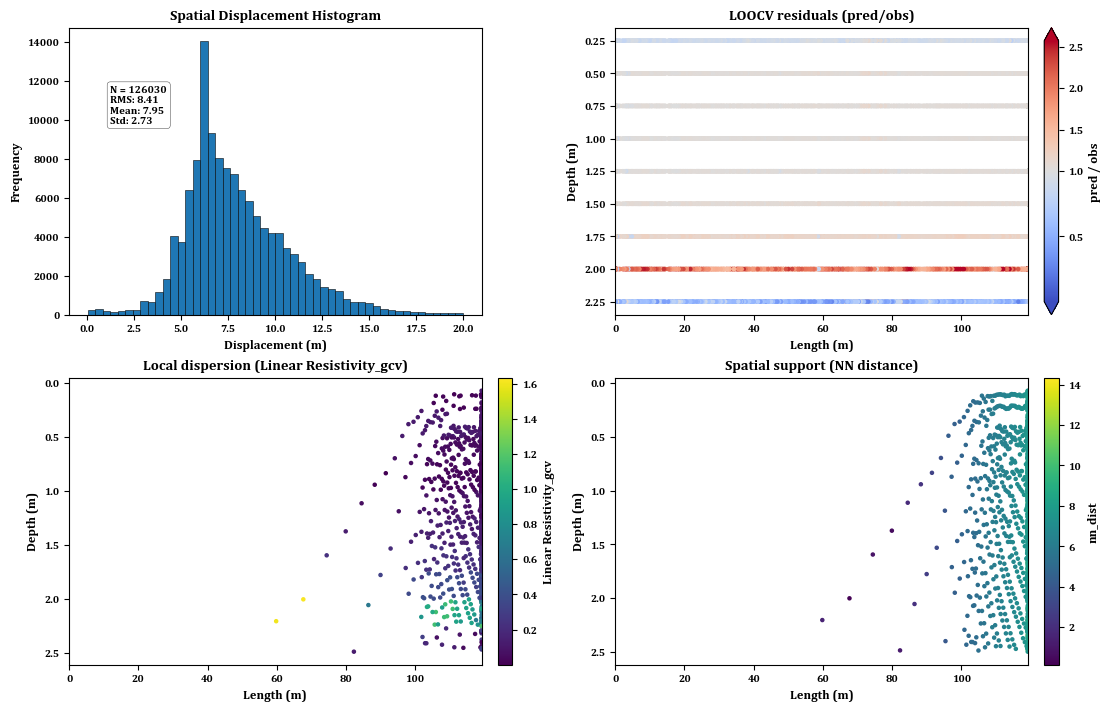

In [16]:
fig, axs = plt.subplots(nrows=2, ncols=2, figsize=(11, 7), constrained_layout=True)

# (top-left) distribution of mesh-to-EMI mapping displacements over the line
totalDists = [d for surv in distList for d in surv]
meshup.mapper.plot_distance_histogram(totalDists, xyAnn=(0.1, 0.8), ax=axs[0, 0])

# --- (optional) leave-one-SOUNDING-out CV: the honest metric for waterborne data.
#     Uncomment the next line, then add  group_col='sounding'  to confidence() below.
# meshup.emi_inv['sounding'] = meshup.emi_inv.groupby(['x', 'y']).ngroup()

line_coord = along_line_coord(final_averaged_df_raw)

# (other three panels) spatial support, local dispersion, LOOCV residuals,
# plus the aggregate interpolation-error metrics for the whole line
results = meshup.confidence(
    'Linear Resistivity',                 # base EMI column in meshup.emi_inv (mapped internally)
    plot=True,
    resid_space='ratio',
    ax=[axs[1, 1], axs[1, 0], axs[0, 1]],  # The local dispersion and Spatial Support plots don't work well with the iterated inversions, so the two more important are in the top row
    savefig=True,
    figpath=figdir,
    plotDepth=True,
    line_coord=line_coord,
    # group_col='sounding',               # <- uncomment with the line above for sounding-wise CV
)

plt.savefig(figdir + 'interpolationErrorPlots.png', dpi=300)

# total interpolation-error summary over the entire line (RMSE / MAE / bias, linear factors, fill fraction)
print(results['loocv_summary'])

0 (0.0 %) measurements outside of +/- 3% error threshold.
Mean of inversion errors is 0.11288256249999999 %


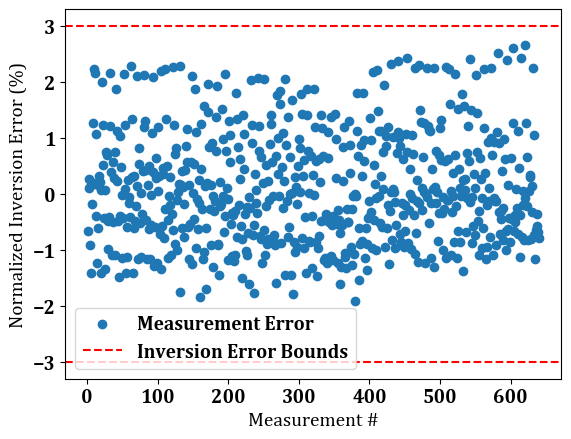

In [17]:
rms_df = pd.DataFrame({'rms_ap_rm1': rms_list})
rms_df.to_csv(dRef + '\\rms_ap_rm1_' + str(k.param['alpha_s']) + '.csv', index = None)
fig, ax = plt.subplots()
numMeas = np.linspace(1, len(errList), len(errList))
ax.scatter(numMeas, errList, label='Measurement Error')
ax.axhline(y=3, linestyle='--', color='r')
ax.axhline(y=-3, linestyle='--', color='r', label='Inversion Error Bounds')
ax.set_xlabel('Measurement #')
ax.set_ylabel('Normalized Inversion Error (%)')
ax.legend()

inverrs = np.array(errList)
baderridx = np.where((inverrs > 3) | (inverrs < -3))
baderrs = inverrs[baderridx]
print(f'{len(baderrs)} ({(len(baderrs)/len(inverrs))*100} %) measurements outside of +/- 3% error threshold.')
print(f'Mean of inversion errors is {np.mean(inverrs)} %')

errDf = pd.DataFrame({'Measurement Number': numMeas, 'Normalized Inv. Error (%)': errList})
errDf.to_csv(dRef + '\\invErr_rm1_' + str(k.param['alpha_s']) + '.csv', index = None)

In [18]:
averaged_list = []

for i, df in enumerate(results_list):  # now each element is a DataFrame
    df = df.copy()
    
    # Subset X ranges
    temp1 = df[(df['X'] > 8.0) & (df['X'] < 9.25)]
    
    for temp, eX_val in zip([temp1], [7]):
        if temp.empty:
            continue
        
        # Create Z bins using 0.1 width (so ±0.05 will fall into same bin)
        temp["Z_bin"] = (temp["Z"] / 0.1).round() * 0.1
        
        # Average numeric columns within Z_bin
        df_avg = temp.groupby("Z_bin", as_index=False).mean(numeric_only=True)
        
        # Add eX, eY, and source info
        df_avg["eX"] = eX_val
        df_avg["eY"] = 12
        df_avg["source"] = i
        
        averaged_list.append(df_avg)

# Combine all
final_averaged_df_inf = pd.concat(averaged_list, ignore_index=True)
final_averaged_df_inf.head(40)

,Z_bin,param,elm_id,region,cellType,X,Y,Z,Resistivity(ohm.m),Resistivity(log10),Sensitivity(log10),Scaled_Sensitivity(log10),Conductivity(mS/m),eX,eY,source
0,-5.3,438.000000,438.000000,1.0,5.0,8.647330,0.0,-5.302793,4.108260,0.613660,-2.992840,-1.609410,243.412053,7,12,0
1,-5.1,336.000000,336.000000,1.0,5.0,8.638440,0.0,-5.107112,3.579120,0.549485,-2.732030,-1.316750,284.973591,7,12,0
2,-4.7,395.000000,395.000000,1.0,5.0,8.619535,0.0,-4.723065,3.576870,0.549200,-2.766155,-1.310780,285.164338,7,12,0
3,-4.5,520.000000,520.000000,1.0,5.0,8.921215,0.0,-4.520400,3.465055,0.533090,-2.494800,-0.985960,297.526865,7,12,0
4,-4.2,266.000000,266.000000,1.0,5.0,8.597693,0.0,-4.174943,3.066600,0.486660,-2.681470,-1.105970,326.094046,7,12,0
5,-4.1,775.000000,775.000000,1.0,5.0,9.193910,0.0,-4.138573,4.080220,0.610680,-2.575440,-0.902880,245.084824,7,12,0
6,-4.0,282.500000,282.500000,1.0,5.0,8.593652,0.0,-4.000357,3.573330,0.548710,-2.533710,-0.908590,285.533341,7,12,0
7,-3.7,221.500000,221.500000,1.0,5.0,8.595138,0.0,-3.660147,2.330325,0.356990,-2.206315,-0.542545,450.234878,7,12,0
8,-3.5,392.000000,392.000000,1.0,5.0,8.603567,0.0,-3.490187,2.557177,0.397700,-2.269660,-0.534887,410.499417,7,12,0
9,-3.2,449.333333,449.333333,1.0,5.0,8.604148,0.0,-3.171416,2.147223,0.322860,-2.203583,-0.377213,484.572586,7,12,0


In [19]:
# Assuming 'electrodes' DataFrame is already defined and has been filtered as per your previous request
# 'filtered' DataFrame is created by filtering 'electrodes'
# filtered = electrodes[electrodes['label'].astype(str).str.contains(r'( 5| 9)')].reset_index(drop=True)
filtered = electrodes[electrodes['label'].astype(str).str.contains(r'( 7)')].reset_index(drop=True)

# Create a mapping series to determine which row of 'filtered' to use
# The index will be 'source' and the values will be '0' for eX=6 and '1' for eX=12
# This assumes that for each source, eX=6 is always followed by eX=12
# The final index into 'filtered' is calculated as 2 * source + eX_index
final_averaged_df_inf['eX_index'] = final_averaged_df_inf['eX'].map({7: 0})
final_averaged_df_inf['filtered_row_index'] = final_averaged_df_inf['source'] + final_averaged_df_inf['eX_index']

# Create dictionaries for fast lookup
x_map = filtered['x'].to_dict()
y_map = filtered['y'].to_dict()

# Map the values to new columns
final_averaged_df_inf['x'] = final_averaged_df_inf['filtered_row_index'].map(x_map)
final_averaged_df_inf['y'] = final_averaged_df_inf['filtered_row_index'].map(y_map)

In [20]:
final_averaged_df_inf.to_csv(dRef + "\\ERT_informed_rm1_" + str(k.param['alpha_s']) + ".csv", index=None)
final_averaged_df_inf

,Z_bin,param,elm_id,region,cellType,X,Y,Z,Resistivity(ohm.m),Resistivity(log10),Sensitivity(log10),Scaled_Sensitivity(log10),Conductivity(mS/m),eX,eY,source,eX_index,filtered_row_index,x,y
0,-5.3,438.000000,438.000000,1.0,5.0,8.647330,0.0,-5.302793,4.108260,0.613660,-2.992840,-1.609410,243.412053,7,12,0,0,0,478704.101165,3.617395e+06
1,-5.1,336.000000,336.000000,1.0,5.0,8.638440,0.0,-5.107112,3.579120,0.549485,-2.732030,-1.316750,284.973591,7,12,0,0,0,478704.101165,3.617395e+06
2,-4.7,395.000000,395.000000,1.0,5.0,8.619535,0.0,-4.723065,3.576870,0.549200,-2.766155,-1.310780,285.164338,7,12,0,0,0,478704.101165,3.617395e+06
3,-4.5,520.000000,520.000000,1.0,5.0,8.921215,0.0,-4.520400,3.465055,0.533090,-2.494800,-0.985960,297.526865,7,12,0,0,0,478704.101165,3.617395e+06
4,-4.2,266.000000,266.000000,1.0,5.0,8.597693,0.0,-4.174943,3.066600,0.486660,-2.681470,-1.105970,326.094046,7,12,0,0,0,478704.101165,3.617395e+06
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2010,-0.6,263.000000,263.000000,1.0,5.0,8.606325,0.0,-0.604468,0.415875,-0.381180,-0.409125,1.768840,2406.083532,7,12,63,0,63,478693.603452,3.617277e+06
2011,-0.5,594.000000,594.000000,1.0,5.0,8.720042,0.0,-0.515232,0.438813,-0.357950,-0.728180,1.731643,2281.307788,7,12,63,0,63,478693.603452,3.617277e+06
2012,-0.4,756.500000,756.500000,1.0,5.0,8.430515,0.0,-0.431223,0.421095,-0.375695,-0.466425,1.957685,2375.535858,7,12,63,0,63,478693.603452,3.617277e+06
2013,-0.2,608.333333,608.333333,1.0,5.0,8.623674,0.0,-0.218188,0.443873,-0.354053,-0.537003,1.874273,2266.294201,7,12,63,0,63,478693.603452,3.617277e+06


In [21]:
for i in range(len(final_averaged_df_inf)):
    final_averaged_df_inf.loc[i, 'X'] = relLinePos[::-1][idx[i]]

print(final_averaged_df_inf['X'].min())
print(final_averaged_df_inf['X'].max())
final_averaged_df_inf

0.0
119.20038855550371


,Z_bin,param,elm_id,region,cellType,X,Y,Z,Resistivity(ohm.m),Resistivity(log10),Sensitivity(log10),Scaled_Sensitivity(log10),Conductivity(mS/m),eX,eY,source,eX_index,filtered_row_index,x,y
0,-5.3,438.000000,438.000000,1.0,5.0,0.000000,0.0,-5.302793,4.108260,0.613660,-2.992840,-1.609410,243.412053,7,12,0,0,0,478704.101165,3.617395e+06
1,-5.1,336.000000,336.000000,1.0,5.0,0.000000,0.0,-5.107112,3.579120,0.549485,-2.732030,-1.316750,284.973591,7,12,0,0,0,478704.101165,3.617395e+06
2,-4.7,395.000000,395.000000,1.0,5.0,0.000000,0.0,-4.723065,3.576870,0.549200,-2.766155,-1.310780,285.164338,7,12,0,0,0,478704.101165,3.617395e+06
3,-4.5,520.000000,520.000000,1.0,5.0,0.000000,0.0,-4.520400,3.465055,0.533090,-2.494800,-0.985960,297.526865,7,12,0,0,0,478704.101165,3.617395e+06
4,-4.2,266.000000,266.000000,1.0,5.0,0.000000,0.0,-4.174943,3.066600,0.486660,-2.681470,-1.105970,326.094046,7,12,0,0,0,478704.101165,3.617395e+06
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2010,-0.6,263.000000,263.000000,1.0,5.0,119.200389,0.0,-0.604468,0.415875,-0.381180,-0.409125,1.768840,2406.083532,7,12,63,0,63,478693.603452,3.617277e+06
2011,-0.5,594.000000,594.000000,1.0,5.0,119.200389,0.0,-0.515232,0.438813,-0.357950,-0.728180,1.731643,2281.307788,7,12,63,0,63,478693.603452,3.617277e+06
2012,-0.4,756.500000,756.500000,1.0,5.0,119.200389,0.0,-0.431223,0.421095,-0.375695,-0.466425,1.957685,2375.535858,7,12,63,0,63,478693.603452,3.617277e+06
2013,-0.2,608.333333,608.333333,1.0,5.0,119.200389,0.0,-0.218188,0.443873,-0.354053,-0.537003,1.874273,2266.294201,7,12,63,0,63,478693.603452,3.617277e+06


In [22]:
#%% 2D Profile Visualziations

## Paths to Files
ERTnc =  final_averaged_df_raw
ERTnc['Conductivity(mS/m)'] = (1/ERTnc['Resistivity(ohm.m)'])*1000
EMIcal = pd.read_csv(eminame)
ERTc = final_averaged_df_inf

dflist = [EMIcal, ERTc] # Names of variables that will be mapped to ERI line
dfnames = ['emi', 'informed'] # Names for each entry in dflist that will be used in the column headers for the combined dataframe

for df in dflist:
    df.rename(columns={'Depth': 'Z'}, inplace=True)
EMIcal.rename(columns={'Depth': 'Z'}, inplace=True)

mapper = ec.er2em.DataMapper(num_neighbors=1, max_distance_xy=5, max_distance_z = 0.25, ckdMethod='num')

result_xy, distances_xy = mapper.mapXYZ(ERTnc, dflist, dfnames, topo_correct=False) # Maps entries in dflist to EMIcal

# Display shift: re-zero the top of the section for plotting as depth.
if result_xy['Z'].max() > 0:
    zAdj = result_xy['Z'].max() + 0.01
    result_xy['Z']  -= zAdj
    emi_grid['Z'] -= zAdj

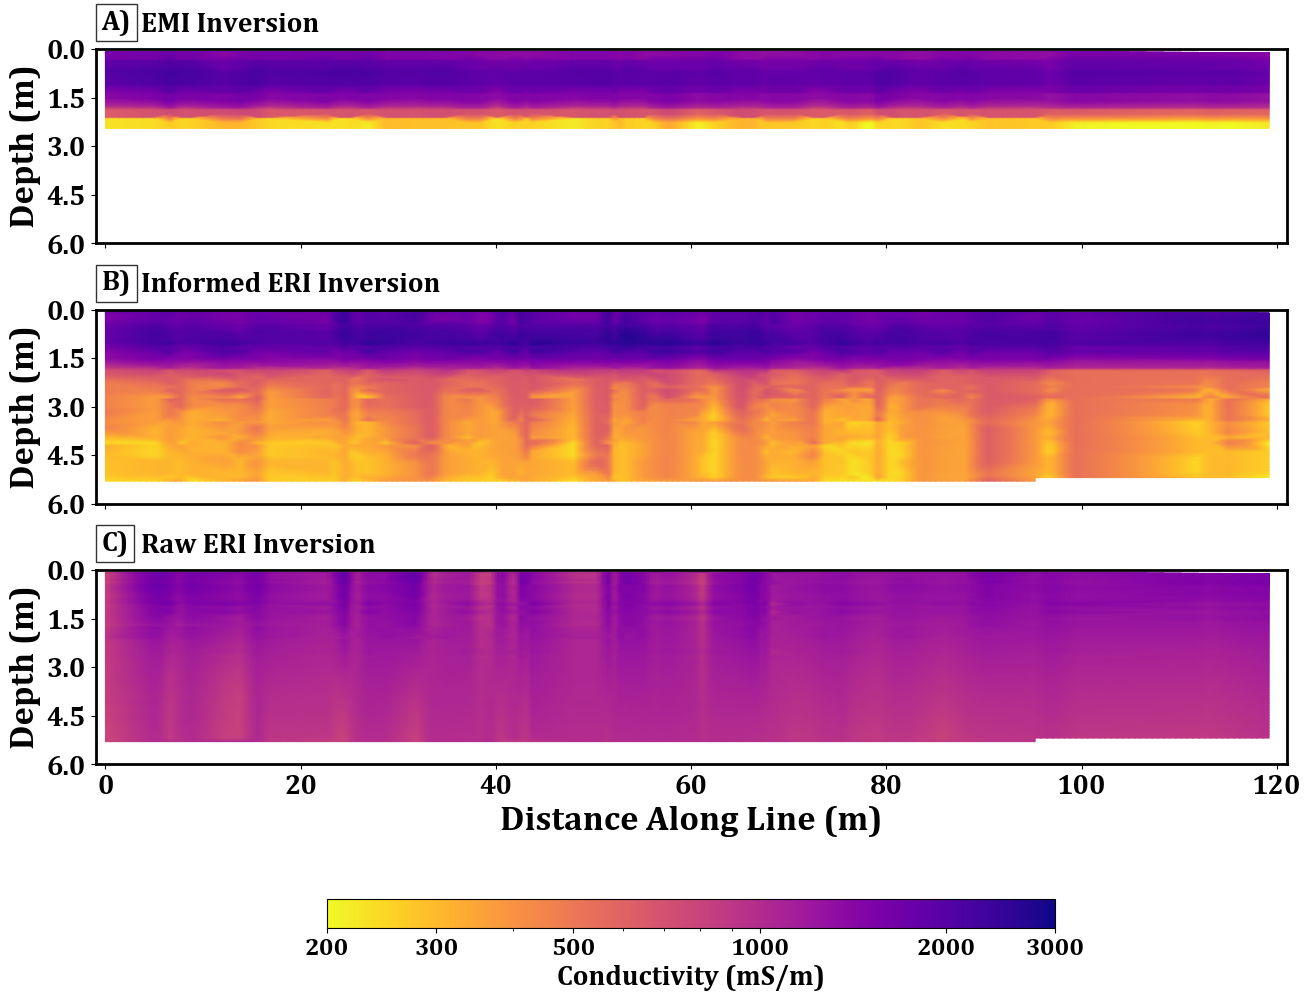

In [23]:
#%% Plot Contours for Each Survey

# Define vmin and vmax for contour plots
vmin, vmax = 200, 3000  # Define Colorbar Limits
xlim_min, xlim_max = -1, 121  # Define Range of x-values in Plots
color_map = "plasma_r"   # Define colormap
contourSmooth = 'smooth'   # 'smooth' for smoothed plots, 'contour' for contour plots
zBounds = [0, 6]   # Define depth bounds for plots
numZticks = 5   # Define number of ticks for depth axis
exportJointCsv = True  # If True, export result_xy as a .csv file with all rows with nan removed
csvDir = datDir    # Path to export Joint CSV file to
aspectRatio = None

ticks = [200, 300, 500, 1000, 2000, 3000]

# Figure with 3 subplots, making the KDE plot thinner
fig, axes = plt.subplots(nrows=3, ncols=1, figsize=(13, 10), constrained_layout=True, sharex=True,
                         gridspec_kw={'height_ratios': [4, 4, 4]})  # Top KDE plot is thin

sf1 = 'A)'
sf2 = 'B)'
sf3 = 'C)'
sf4 = r'EMI Inversion'
sf5 = r'Informed ERI Inversion'
sf6 = r'Raw ERI Inversion'

plot_contour(axes[0], result_xy['X'], -1*result_xy['Z'],
             result_xy['emi_Linear Conductivity'], vmin, vmax, plotTyp='quad',
             title='', xmin=xlim_min, xmax=xlim_max, cmap=color_map, cbbool=False, cbLabel='Conductivity (mS/m)', cbTicks=ticks, ri=-1*result_xy['Z'], riThresh=2.5, xlabel='', subfig=sf1, subfig2=sf4,
             zbounds=zBounds, numZtick=numZticks, contourOrSmooth=contourSmooth, plotMeas=False, aspect=aspectRatio)

plot_contour(axes[1], result_xy['X'], -1*result_xy['Z'],
             result_xy['informed_Conductivity(mS/m)'], vmin, vmax, plotTyp='quad',
             title='', xmin=xlim_min, xmax=xlim_max, cmap=color_map, cbbool=False, cbLabel='Conductivity (mS/m)', cbTicks=ticks, ri=None, riThresh=None, xlabel='', subfig=sf2, subfig2=sf5,
             zbounds=zBounds, numZtick=numZticks, contourOrSmooth=contourSmooth, plotMeas=False, aspect=aspectRatio)

plot_contour(axes[2], result_xy['X'], -1*result_xy['Z'],
             result_xy['Conductivity(mS/m)'], vmin, vmax, plotTyp='quad',
             title='', xmin=xlim_min, xmax=xlim_max, cmap=color_map, cbbool=True, cbLabel='Conductivity (mS/m)', cbTicks=ticks, ri=None, riThresh=None,  xlabel='Distance Along Line (m)', subfig=sf3, subfig2=sf6,
             zbounds=zBounds, numZtick=numZticks, contourOrSmooth=contourSmooth, plotMeas=False, aspect=aspectRatio)

# Save and display
plt.savefig(figdir + 'combined_eri_infEMI_ncEMI_plot_interp.png', dpi=300)
plt.show()

if exportJointCsv:
    trim_result = result_xy.copy(deep=True)
    # trim_result.dropna(inplace=True, subset=['cal_Linear Conductivity_geom', 'nc_Linear Conductivity_geom'])
    trim_result.to_csv(csvDir + 'EMI_calERI_ncERI_df.csv', index=False)

## Statistical Analysis and Validation

             Informed (ERI vs EMI)  Raw (ERI vs EMI)
KGE_np                        0.87              0.59
KGE_alpha                     0.98              0.94
KGE_beta                      1.04              1.10
KGE_r                         0.88              0.60
KGE_2009                      0.83              0.09
KGE_2012                      0.80              0.08
NSE                           0.80             -0.28
R²                            0.91              0.39
Pearson r                     0.95              0.62
Spearman r                    0.88              0.60
ME                            0.12              0.27
MAE                           0.13              0.37
RMSE                          0.18              0.45
NRMSE_range                   0.16              0.40


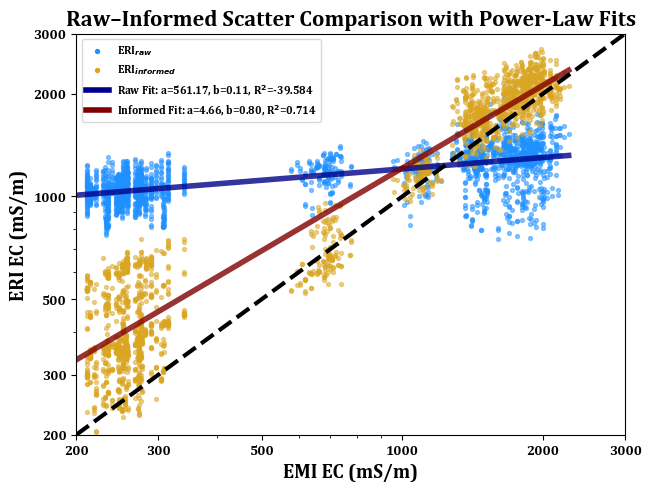

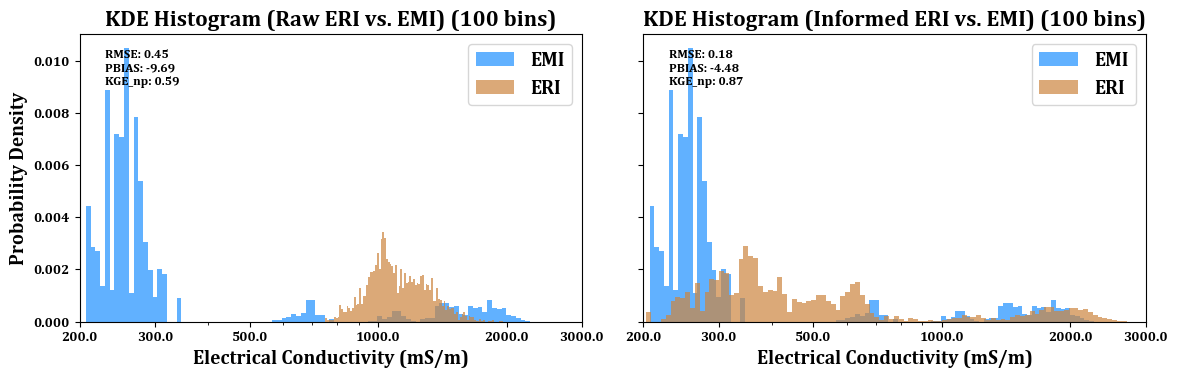

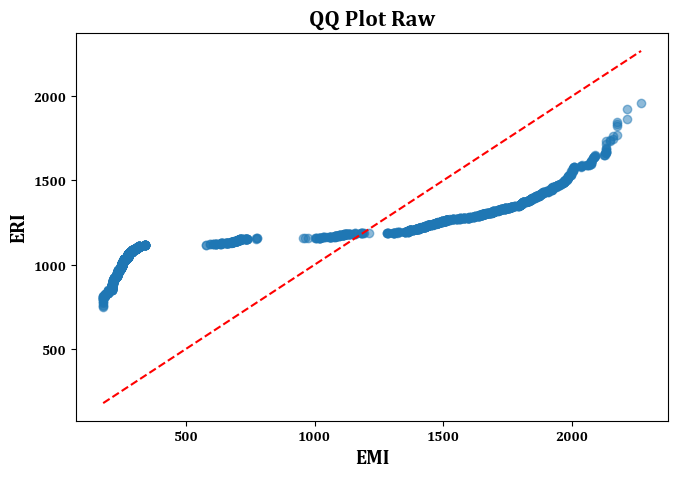

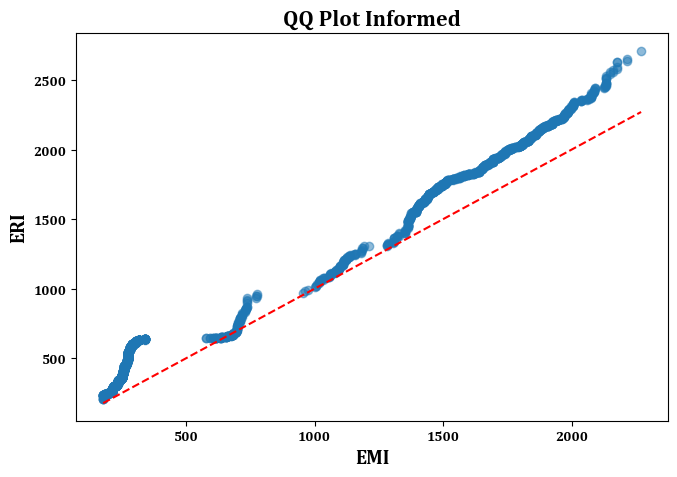


Median Difference: 569.169 mS/m
Upper Limit of Agreement: 942.523 mS/m
Lower Limit of Agreement: -867.722 mS/m

Median Difference: 135.028 mS/m
Upper Limit of Agreement: 607.01 mS/m
Lower Limit of Agreement: -118.891 mS/m


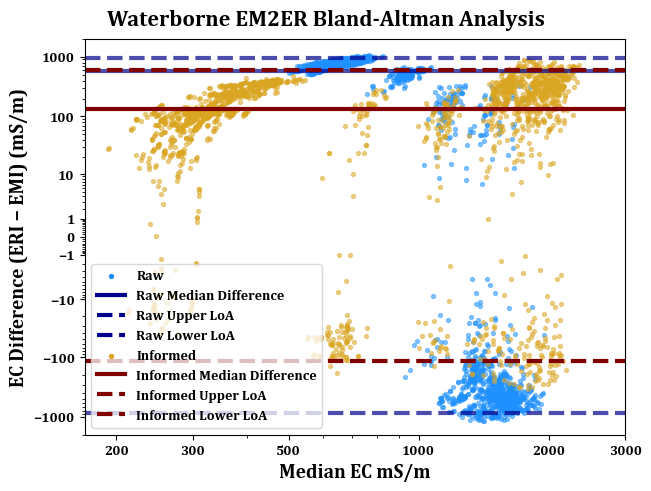

In [24]:
nonparam = True
site = 'waterborne_em2er'

ticks = [200, 300, 500, 1000, 2000, 3000]

logList = [1, 1]   # List dictating whether to use log (1) or linear (0) scales for the Bland-Altman plots

j = ec.vse.EConfluxStats(datDir + 'EMI_calERI_ncERI_df.csv', 'emi_Linear Conductivity', 'Conductivity(mS/m)', 'informed_Conductivity(mS/m)', 
                  drop_flag_col=None, informingMethod='EMI', informedMethod='ERI', ticks=ticks, **fontkwDict)

# Get metrics table
print(j.metrics(logOrlin='log', decompKGE=True))

# Make plots

dbounds = [0, 0.5, 1.0, 1.6, 2.0, 3.2, 5.2]
cmap = 'viridis'

j.scatter_plots(log=True, grayscale=False, figname=figdir + site + '_scatter.png')

j.kde_histograms(figname=figdir + site + '_kde.png', nbins=100)

j.qq_plot(j.X, j.y, xlabel="ER", ylabel="Raw EM", title="QQ Plot Raw", figname=figdir + site + '_rawQQ.png')

j.qq_plot(j.X, j.Y, xlabel="ER", ylabel="Informed EM", title="QQ Plot Informed", figname=figdir + site + '_infQQ.png')

### Bland-Altman Plots ###
fig, ax = plt.subplots(layout='constrained')

rawKws = {'label': 'Raw', 'color': 'dodgerblue', 'alpha': 0.5}
rawLineKws = {'color': 'darkblue', 'alpha': 0.7, 'linestyle': ['-', '--'], 'linewidth': 3, 'label': ['Raw Median Difference', 'Raw Upper LoA', 'Raw Lower LoA']}
infKws = {'label': 'Informed', 'color': 'goldenrod', 'alpha': 0.5}
infLineKws = {'color': 'maroon', 'alpha': 1, 'linestyle': ['-', '--'], 'linewidth': 3, 'label': ['Informed Median Difference', 'Informed Upper LoA', 'Informed Lower LoA']}

# Bland-Altman for raw EM vs ER
j.bland_altman(j.y, j.X, ax=ax, ymin=-2000, ymax=2000, marker='o', markersize=8, xmin=None, xmax=None, savefig=False, figname=None,
               xticks=ticks, logList=logList, nonparam=nonparam, legendParams={'plot': True, 'loc': 'lower left'}, linekwargs=rawLineKws, **rawKws)

# Bland-Altman for informed EM vs ER
j.bland_altman(j.Y, j.X, ax=ax, ymin=-2000, ymax=2000, marker='o', markersize=8, xmin=None, xmax=None, savefig=False, figname=None, 
               xticks=ticks, logList=logList, nonparam=nonparam, legendParams={'plot': True, 'loc': 'lower left'}, linekwargs=infLineKws, **infKws)

# Plot Detailing
if dbounds is not None:
    if plt.get_cmap(cmap).N == 256:
        dcmap = plt.get_cmap(cmap, len(dbounds))
    norm = colors.BoundaryNorm(dbounds, ncolors=len(dbounds))
else:
    norm = colors.Normalize(vmin=0, vmax=abs(j.data['Z'].min()))
            
cmmapable = cm.ScalarMappable(norm, dcmap)

fig.suptitle('Waterborne EM2ER Bland-Altman Analysis', **titleFontKws)
ax.set_ylabel("EC Difference " + f"({j.informedMethod} − {j.informingMethod}) ({j.units})", **labelFontKws)
if nonparam:
    ax.set_xlabel("Median EC " + (f"{j.units}"), **labelFontKws)
else:
    ax.set_xlabel("Mean EC " + (f"{j.units}"), **labelFontKws)

plt.savefig(figdir + site + '_blandaltman.png', dpi=300)

Ground-truth validation vs informed_Conductivity(mS/m)
  points compared: 24 / 24
  log10 RMSE / MAE / bias: 0.353 / 0.352 / -0.352
  linear factors RMSE / MAE / bias: x2.26 / x2.25 / x0.45
  median model/observed ratio: 0.463


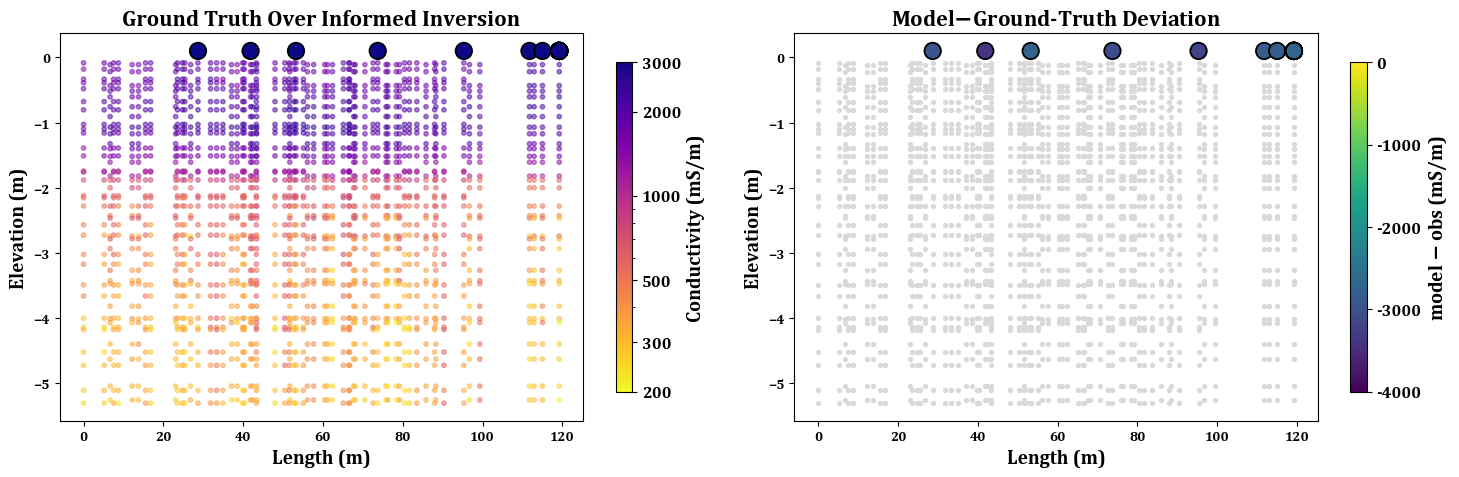

,x,y,Z,observed,model,n_elements,local_logstd,dev_linear,ratio,dev_log10,abs_dev_log10
0,478699.7015,3617364.754,0.1,5050.0,2089.187937,8,0.045918,-2960.812063,0.413701,-0.383314,0.383314
1,478698.7140,3617354.439,0.1,5050.0,1671.822621,8,0.025755,-3378.177379,0.331054,-0.480101,0.480101
2,478698.5744,3617341.793,0.1,5050.0,2291.318769,8,0.047089,-2758.681231,0.453726,-0.343206,0.343206
3,478694.1357,3617321.956,0.1,5050.0,1973.149798,8,0.038998,-3076.850202,0.390723,-0.408131,0.408131
4,478692.2117,3617303.339,0.1,5060.0,1878.693803,8,0.049305,-3181.306197,0.371283,-0.430295,0.430295
5,478691.9623,3617287.556,0.1,5040.0,2210.433568,8,0.013996,-2829.566432,0.438578,-0.357953,0.357953
6,478692.5344,3617278.948,0.1,5060.0,2203.358684,8,0.014131,-2856.641316,0.435446,-0.361065,0.361065
7,478694.1542,3617264.895,0.1,5010.0,2342.787100,8,0.016618,-2667.212900,0.467622,-0.330105,0.330105
8,478695.5711,3617252.437,0.1,5060.0,2342.818386,8,0.016618,-2717.181614,0.463008,-0.334412,0.334412
9,478698.4270,3617237.826,0.1,5060.0,2342.824296,8,0.016618,-2717.175704,0.463009,-0.334411,0.334411


In [25]:
gwfpath = r"C:\Users\Chris\Documents\GitHub\EConflux\examples\waterborne_em2er\Electrode mapping from Boat GPS\mapped_1bSpC_points.csv"
gwDat = pd.read_csv(gwfpath)
gwDat['SpC_mSm'] = gwDat['SpC_mS_cm'] * 100
gwDat['Z'] = np.ones(len(gwDat))*0.1

j.ground_truth_check(gwDat, 'SpC_mSm', model_col='informed_Conductivity(mS/m)', cmap='plasma_r', dev_space='difference', devCmap='viridis', figname=figdir+'informed_groundTruthDiff.png', cbticks=ticks, diffticks=[-4000, -3000, -2000, -1000, 0])

Ground-truth validation vs Conductivity(mS/m)
  points compared: 24 / 24
  log10 RMSE / MAE / bias: 0.551 / 0.549 / -0.549
  linear factors RMSE / MAE / bias: x3.56 / x3.54 / x0.28
  median model/observed ratio: 0.291


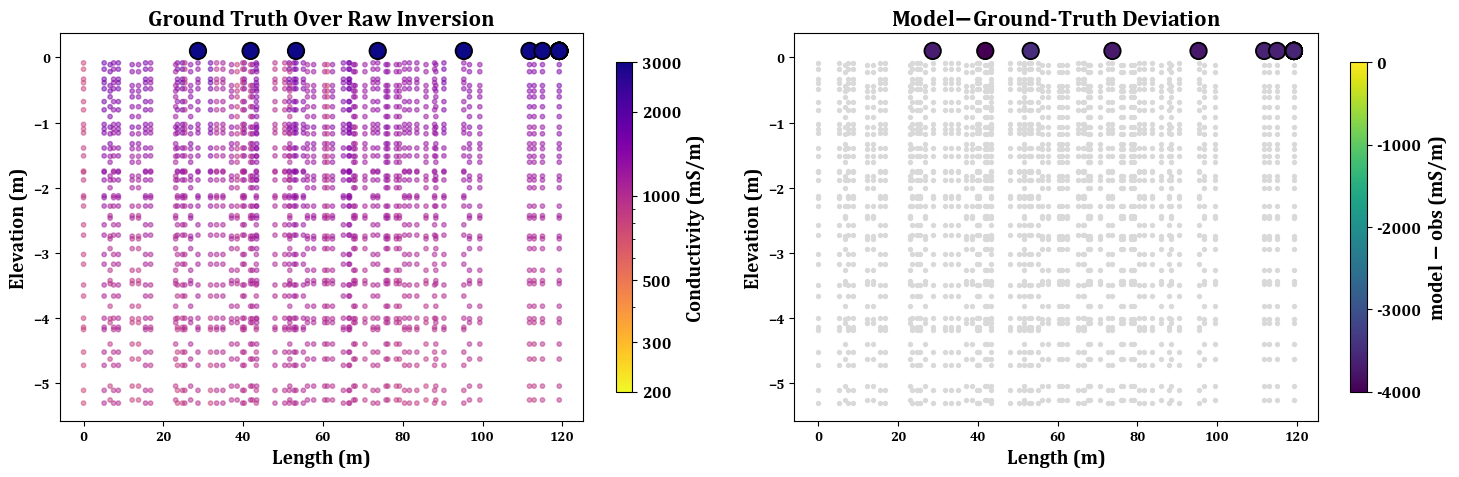

,x,y,Z,observed,model,n_elements,local_logstd,dev_linear,ratio,dev_log10,abs_dev_log10
0,478699.7015,3617364.754,0.1,5050.0,1365.103050,8,0.011252,-3684.896950,0.270317,-0.568126,0.568126
1,478698.7140,3617354.439,0.1,5050.0,888.267735,8,0.017591,-4161.732265,0.175895,-0.754747,0.754747
2,478698.5744,3617341.793,0.1,5050.0,1554.105113,8,0.022236,-3495.894887,0.307744,-0.511811,0.511811
3,478694.1357,3617321.956,0.1,5050.0,1318.286469,8,0.008755,-3731.713531,0.261047,-0.583282,0.583282
4,478692.2117,3617303.339,0.1,5060.0,1324.768342,8,0.008049,-3735.231658,0.261812,-0.582011,0.582011
5,478691.9623,3617287.556,0.1,5040.0,1427.804602,8,0.026116,-3612.195398,0.283295,-0.547762,0.547762
6,478692.5344,3617278.948,0.1,5060.0,1430.161076,8,0.022231,-3629.838924,0.282641,-0.548766,0.548766
7,478694.1542,3617264.895,0.1,5010.0,1474.503713,8,0.022653,-3535.496287,0.294312,-0.531192,0.531192
8,478695.5711,3617252.437,0.1,5060.0,1474.424701,8,0.022653,-3585.575299,0.291388,-0.535528,0.535528
9,478698.4270,3617237.826,0.1,5060.0,1474.409696,8,0.022653,-3585.590304,0.291385,-0.535532,0.535532


In [26]:
j.ground_truth_check(gwDat, 'SpC_mSm', model_col='Conductivity(mS/m)', cmap='plasma_r', dev_space='difference', devCmap='viridis', figname=figdir+'raw_groundTruthDiff.png', cbticks=ticks, diffticks=[-4000, -3000, -2000, -1000, 0])